# **Car Insurance Claim Risk Prediction: Machine Learning, GLM and Generalist Models for Underwriting and Fraud-Risk Triage**

# **Part 1 - Business Problem**

**Context.** An auto insurer must decide, at policy issuance and renewal, how likely each policyholder is to file a claim in the next 6 months. Today, pricing and underwriting rely on static rules and broad actuarial tables, which can't capture the interaction between policyholder profile (age, tenure, city density), vehicle characteristics (make, model, engine, safety features, NCAP rating) and claim behavior. The result is mispriced policies, avoidable loss ratio, and manual reviews that are not prioritized by risk.

**Objective.** Build a binary classification model that estimates the probability of `is_claim` for each policyholder. The score will be used to:

- Support risk-based pricing and underwriting decisions.
- Prioritize high-risk policies for manual review and fraud-risk triage.
- Reduce loss ratio without rejecting good customers unnecessarily.

**Statistical (GLM) approach.**

- Poisson GLM with a log link and a log exposure offset (`policy_tenure`), the standard actuarial approach to claim frequency, with robust standard errors (modified Poisson) because the target is binary.
- Incidence rate ratios (IRR) for each risk factor, so underwriters and pricing teams can read the effect of each variable in business terms.
- Binomial (logit) GLM as a benchmark, to compare discrimination and calibration against the Poisson model.

**Machine learning approach.**

- Baselines: Poisson GLM, Logistic Regression and Decision Tree.
- Tree ensembles and gradient boosting: Random Forest, XGBoost, LightGBM and CatBoost, which handle categorical features well.
- Class imbalance handling (the positive class is rare): class weights, resampling and threshold tuning.
- Probability calibration, so the score can be used for pricing.
- Model comparison: interpretable GLMs against boosted models on the same validation scheme, to measure how much predictive lift is gained over the actuarial standard.

**Generalist models approach.**

- A tabular foundation model (such as TabPFN) as a strong benchmark with no manual tuning.
- An LLM as an explanation layer: it turns each score and its top SHAP drivers into a plain-language justification for underwriters and analysts.
- An LLM as a triage assistant: it summarizes the risk profile of flagged policies to speed up manual review.
- Safe use: the LLM does not make the decision. It only explains and summarizes the outputs of the validated ML model, with no personal data sent to external APIs and with human review.

**Success metrics.** PR-AUC and ROC-AUC (the main metrics given the imbalance), Recall and Precision at the chosen threshold, F1, calibration (Brier score and observed vs predicted claim rate), and estimated business impact (claims captured in the top decile of risk).

**Dataset note.** The target `is_claim` indicates whether a claim was filed, not whether the claim was fraudulent. There is no fraud label in the data, so the project is framed as claim risk prediction, with fraud-risk triage as a downstream use of the score.

In [1]:
import time
import joblib
import sys
import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score,average_precision_score,balanced_accuracy_score,brier_score_loss,f1_score,precision_score,recall_score,roc_auc_score)
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid, StratifiedKFold, cross_validate
from tqdm.auto import tqdm
from sklearn.base import clone
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.metrics import auc, roc_curve
from sklearn.metrics import precision_recall_curve
from scipy.stats import loguniform, randint
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

c:\Users\rafae\Documents\Projetos_data_science_IA\machine_learning\Car Insurance Claim Prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Part 2 - Database

In [2]:
# Load the treated dataset
df = pd.read_csv(r"C:\Users\rafae\Documents\Projetos_data_science_IA\machine_learning\Car Insurance Claim Prediction\data\train_outliers_tratados.csv")
df

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,ID58588,0.355089,0.13,0.644231,C8,8794,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
58588,ID58589,1.199642,0.02,0.519231,C14,7788,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58589,ID58590,1.162273,0.05,0.451923,C5,34738,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58590,ID58591,1.236307,0.14,0.557692,C8,8794,1,B2,M6,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,K Series Dual jet,2,No,Yes,No,Yes,No,Drum,1197,4,Manual,5,Electric,4.8,3845,1735,1530,1335,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0


In [3]:
df.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


In [4]:
df.tail()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
58587,ID58588,0.355089,0.13,0.644231,C8,8794,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
58588,ID58589,1.199642,0.02,0.519231,C14,7788,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58589,ID58590,1.162273,0.05,0.451923,C5,34738,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58590,ID58591,1.236307,0.14,0.557692,C8,8794,1,B2,M6,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,K Series Dual jet,2,No,Yes,No,Yes,No,Drum,1197,4,Manual,5,Electric,4.8,3845,1735,1530,1335,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
58591,ID58592,0.124429,0.02,0.442308,C8,8794,3,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,6,Power,5.2,4300,1790,1635,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0


In [5]:
df.dtypes

policy_id                               str
policy_tenure                       float64
age_of_car                          float64
age_of_policyholder                 float64
area_cluster                            str
population_density                    int64
make                                  int64
segment                                 str
model                                   str
fuel_type                               str
max_torque                              str
max_power                               str
engine_type                             str
airbags                               int64
is_esc                                  str
is_adjustable_steering                  str
is_tpms                                 str
is_parking_sensors                      str
is_parking_camera                       str
rear_brakes_type                        str
displacement                          int64
cylinder                              int64
transmission_type               

# Part 3 - Pre-processamento dados

In [6]:
# null count per column, only columns with nulls / contagem de nulos por coluna, só as que têm
nulos = df.isna().sum()
nulos[nulos > 0].to_frame("nulos")

# duplicated rows and duplicated identifiers / linhas duplicadas e identificadores duplicados
print("linhas duplicadas / duplicated rows:", df.duplicated().sum())
print("policy_id repetidos / repeated ids:", df["policy_id"].duplicated().sum())

linhas duplicadas / duplicated rows: 0
policy_id repetidos / repeated ids: 0


In [7]:
# unique values per text column, n visible / valores únicos por coluna de texto, com n visível
texto = df.select_dtypes(exclude="number").drop(columns="policy_id")
pd.DataFrame({
    "n_unicos": texto.nunique(),
    "exemplos": texto.apply(lambda s: s.unique()[:4].tolist()),
})

,n_unicos,exemplos
area_cluster,22,"[C1, C2, C3, C4]"
segment,6,"[A, C1, C2, B2]"
model,11,"[M1, M2, M3, M4]"
fuel_type,3,"[CNG, Petrol, Diesel]"
max_torque,9,"[60Nm@3500rpm, 113Nm@4400rpm, 91Nm@4250rpm, 25..."
max_power,9,"[40.36bhp@6000rpm, 88.50bhp@6000rpm, 67.06bhp@..."
engine_type,11,"[F8D Petrol Engine, 1.2 L K12N Dualjet, 1.0 SC..."
is_esc,2,"[No, Yes]"
is_adjustable_steering,2,"[No, Yes]"
is_tpms,2,"[No, Yes]"


In [8]:
# type, null count, unique values and example per column / tipo, nulos, valores únicos e exemplo por coluna
tipos = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "n_unicos": df.nunique(),
    "exemplo": df.iloc[0],
})
tipos

,tipo,nulos,n_unicos,exemplo
policy_id,str,0,58592,ID00001
policy_tenure,float64,0,58592,0.515874
age_of_car,float64,0,49,0.05
age_of_policyholder,float64,0,75,0.644231
area_cluster,str,0,22,C1
population_density,int64,0,22,4990
make,int64,0,5,1
segment,str,0,6,A
model,str,0,11,M1
fuel_type,str,0,3,CNG


In [9]:
# how many columns per type / quantas colunas por tipo
df.dtypes.astype(str).value_counts().to_frame("colunas")

,colunas
str,28
int64,12
float64,4


# Part 4 - Limpeza de dados 

In [10]:
# null count and share per column / contagem e proporção de nulos por coluna
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "pct": (df.isna().mean() * 100).round(2),
})

print("n =", len(df), "| colunas com nulos / columns with nulls:", int((nulos["nulos"] > 0).sum()))
nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)

n = 58592 | colunas com nulos / columns with nulls: 0


,nulos,pct


In [11]:
# rows with at least one null / linhas com pelo menos um nulo
linhas_nulas = df.isna().any(axis=1)
print("linhas afetadas / affected rows:", int(linhas_nulas.sum()), f"({linhas_nulas.mean() * 100:.2f}%)")

linhas afetadas / affected rows: 0 (0.00%)


In [12]:
# placeholder strings that mean "missing" / textos que significam "ausente"
ausentes = {"", " ", "na", "n/a", "nan", "null", "none", "unknown", "?", "-"}

# count placeholders per text column / conta esses textos por coluna de texto
texto = df.select_dtypes(exclude="number")
disfarcados = texto.apply(lambda s: s.astype(str).str.strip().str.lower().isin(ausentes).sum())

disfarcados[disfarcados > 0].to_frame("valores_ausentes_disfarcados")

,valores_ausentes_disfarcados


In [13]:
# zeros in numeric columns, n visible / zeros em colunas numéricas, com n visível
num = df.select_dtypes("number")
zeros = (num == 0).sum()
zeros[zeros > 0].to_frame("zeros")

,zeros
age_of_car,5257
ncap_rating,19097
is_claim,54844


In [14]:
# repeated identifiers and fully repeated rows / identificadores repetidos e linhas totalmente repetidas
print("n =", len(df))
print("policy_id repetidos / repeated ids:", df["policy_id"].duplicated().sum())
print("linhas duplicadas / duplicated rows:", df.duplicated().sum())

n = 58592
policy_id repetidos / repeated ids: 0
linhas duplicadas / duplicated rows: 0


In [15]:
# rows identical in every column except the identifier / linhas iguais em todas as colunas, exceto o identificador
cols_sem_id = df.columns.drop("policy_id")
dup_sem_id = df.duplicated(subset=cols_sem_id, keep=False)

print("linhas envolvidas / rows involved:", int(dup_sem_id.sum()), f"({dup_sem_id.mean() * 100:.2f}%)")

linhas envolvidas / rows involved: 0 (0.00%)


In [16]:
# do identical rows agree on the target? / as linhas idênticas concordam no alvo?
grupos = df[dup_sem_id].groupby(list(cols_sem_id.drop("is_claim")))["is_claim"].agg(["count", "nunique"])
print("grupos de linhas idênticas / groups:", len(grupos))
print("grupos com alvo diferente / groups with conflicting target:", int((grupos["nunique"] > 1).sum()))

grupos de linhas idênticas / groups: 0
grupos com alvo diferente / groups with conflicting target: 0


# **Part 5 - Feature Engineering**

In [17]:
# columns before encoding, to prove none is added / colunas antes da codificação, para provar que nenhuma é adicionada
cols_antes = df.columns.tolist()

# every text column except the identifier, plus make (brand code) / toda coluna de texto exceto o identificador, mais make (código de marca)
cat_cols = df.select_dtypes(exclude="number").columns.drop("policy_id").tolist() + ["make"]

print(len(cat_cols), "colunas / columns")
df[cat_cols].nunique().sort_values().to_frame("n_categorias").T

28 colunas / columns


,is_esc,is_front_fog_lights,transmission_type,rear_brakes_type,is_parking_camera,is_parking_sensors,is_tpms,is_adjustable_steering,is_driver_seat_height_adjustable,is_power_steering,is_central_locking,is_power_door_locks,is_brake_assist,is_rear_window_defogger,is_rear_window_washer,is_rear_window_wiper,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,fuel_type,steering_type,make,segment,max_torque,max_power,model,engine_type,area_cluster
n_categorias,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,3,3,5,6,9,9,11,11,22


In [18]:
# encode in place, one encoder per column kept for the Kaggle test set / codifica no lugar, um encoder por coluna guardado para o teste do Kaggle
encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    encoders[col] = le

# View the encoders / Veja os codificadores
le    

Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Holds the label for each class.","ndarray[object](5,)","['1','2','3','4','5']"


In [19]:
# same columns in the same order / mesmas colunas na mesma ordem
print("colunas iguais / same columns:", df.columns.tolist() == cols_antes)
print("formato / shape:", df.shape)

# text columns left, expected only the identifier / colunas de texto que sobraram, esperado só o identificador
print(df.select_dtypes(exclude="number").columns.tolist())

colunas iguais / same columns: True
formato / shape: (58592, 44)
['policy_id']


In [20]:
# mapping category to number, example with fuel_type / mapeamento categoria para número, exemplo com fuel_type
le = encoders["fuel_type"]
dict(zip(le.classes_, le.transform(le.classes_)))

{'CNG': np.int64(0), 'Diesel': np.int64(1), 'Petrol': np.int64(2)}

In [21]:
# encoded values per column, a quick sanity check / valores codificados por coluna, checagem rápida
df[["fuel_type", "segment", "is_esc", "max_torque", "area_cluster"]].head()

,fuel_type,segment,is_esc,max_torque,area_cluster
0,0,0,0,5,0
1,0,0,0,5,11
2,0,0,0,5,15
3,2,3,1,0,16
4,2,0,0,8,17


In [22]:
# Save the encoders for later use, e.g. for the Kaggle test set / Salva os codificadores para uso posterior, ex. para o teste do Kaggle
# save the encoders for the Kaggle test set / salva os encoders para o teste do Kaggle
joblib.dump(encoders, r"C:\Users\rafae\Documents\Projetos_data_science_IA\machine_learning\Car Insurance Claim Prediction\models\label_encoders.joblib")

# View the encoders / Veja os codificadores
df

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,0,4990,0,0,0,0,5,2,6,2,0,0,0,1,0,1,796,3,1,5,2,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0
1,ID00002,0.672619,0.02,0.375000,11,27003,0,0,0,0,5,2,6,2,0,0,0,1,0,1,796,3,1,5,2,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0
2,ID00003,0.841110,0.02,0.384615,15,4076,0,0,0,0,5,2,6,2,0,0,0,1,0,1,796,3,1,5,2,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0
3,ID00004,0.900277,0.11,0.432692,16,21622,0,3,3,2,0,6,2,2,1,1,0,1,1,1,1197,4,0,5,0,4.8,3995,1735,1515,1335,1,0,0,1,1,1,1,1,1,1,1,1,2,0
4,ID00005,0.596403,0.11,0.634615,17,34738,1,0,4,2,8,5,0,2,0,0,0,0,1,1,999,3,0,5,0,5.0,3731,1579,1490,1155,0,0,0,0,0,1,1,1,0,1,1,1,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,ID58588,0.355089,0.13,0.644231,20,8794,1,0,4,2,8,5,0,2,0,0,0,0,1,1,999,3,0,5,0,5.0,3731,1579,1490,1155,0,0,0,0,0,1,1,1,0,1,1,1,2,0
58588,ID58589,1.199642,0.02,0.519231,5,7788,0,0,0,0,5,2,6,2,0,0,0,1,0,1,796,3,1,5,2,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0
58589,ID58590,1.162273,0.05,0.451923,17,34738,0,0,0,0,5,2,6,2,0,0,0,1,0,1,796,3,1,5,2,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0
58590,ID58591,1.236307,0.14,0.557692,20,8794,0,2,7,2,0,6,8,2,0,1,0,1,0,1,1197,4,1,5,0,4.8,3845,1735,1530,1335,1,0,0,0,1,1,1,1,1,1,1,1,2,0


# **Part 6 - Selecionando coluna alvo**

In [23]:
# features and target, policy_id is an identifier and stays out / variáveis e alvo, policy_id é identificador e fica de fora
X = df.drop(["is_claim", "policy_id"], axis=1)
y = df["is_claim"]

In [24]:
X.shape

(58592, 42)

In [25]:
y.shape

(58592,)

# Part 7 - Treino e teste divisão

In [26]:
"""Train and test split for the new notebook / divisão em treino e teste para o novo notebook."""

# train and test split, test stays untouched until the final evaluation / divisão em treino e teste, o teste fica intacto até a avaliação final
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,  # 20% for testing / 20% para teste
    random_state=42,  # reproducibility / reprodutibilidade
    stratify=y  # ensures balanced split / garante divisão balanceada
)

In [27]:
# check shapes / verifica os formatos
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(46873, 42) (11719, 42)
(46873,) (11719,)


In [28]:
# class distribution after split / distribuição das classes após a divisão
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

is_claim
0    0.93604
1    0.06396
Name: proportion, dtype: float64
is_claim
0    0.936001
1    0.063999
Name: proportion, dtype: float64


# **Part 8 - Model Machine learning**

In [29]:
# numeric columns are imputed, text columns are one-hot encoded / colunas numéricas são imputadas, colunas de texto recebem one-hot
preprocessador = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), make_column_selector(dtype_include=np.number)),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            make_column_selector(dtype_exclude=np.number),
        ),
    ]
)

# preprocessing and model in a single object / pré-processamento e modelo em um único objeto
pipeline = Pipeline(
    steps=[
        ("preprocessador", preprocessador),
        ("modelo", HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
    ]
)

# search space, prefix modelo__ points to the pipeline step / espaço de busca, o prefixo modelo__ aponta para a etapa do pipeline
espaco = {
    "modelo__learning_rate": loguniform(0.01, 0.2),
    "modelo__max_iter": randint(100, 500),
    "modelo__max_depth": randint(2, 7),
    "modelo__max_leaf_nodes": randint(8, 40),
    "modelo__min_samples_leaf": randint(20, 200),
    "modelo__l2_regularization": loguniform(1e-3, 10),
}

# stratified folds keep the claim rate in every fold / folds estratificados mantêm a taxa de sinistro em cada fold
validacao_cruzada = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# random search scored by PR-AUC, the metric used to rank models / busca aleatória pontuada por PR-AUC, a métrica usada no ranking
busca = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=espaco,
    n_iter=40,
    scoring="average_precision",
    cv=validacao_cruzada,
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

# cross-validation inside the search replaces the validation split / a validação cruzada dentro da busca substitui o split de validação
inicio = time.time()
busca.fit(X_train, y_train)
segundos = time.time() - inicio

# best cross-validated score and parameters / melhor score da validação cruzada e parâmetros
print(f"melhor PR-AUC na validação cruzada / best CV PR-AUC: {busca.best_score_:.4f} ({segundos:.0f}s)")
for parametro, valor in busca.best_params_.items():
    print(f"{parametro}: {valor}")

Fitting 5 folds for each of 40 candidates, totalling 200 fits
melhor PR-AUC na validação cruzada / best CV PR-AUC: 0.1041 (58s)
modelo__l2_regularization: 6.245139574743075
modelo__learning_rate: 0.18043311207136256
modelo__max_depth: 3
modelo__max_iter: 364
modelo__max_leaf_nodes: 33
modelo__min_samples_leaf: 72


In [30]:
"""Evaluate the tuned pipeline on the test set / avalia o pipeline ajustado no conjunto de teste."""

# share of policies flagged by ranking / proporção de apólices marcadas por ranking
frac_alerta = 0.20

# best pipeline refit on the whole training part / melhor pipeline reajustado em toda a parte de treino
melhor_pipeline = busca.best_estimator_

# claim probability on the test set / probabilidade de sinistro no teste
proba = melhor_pipeline.predict_proba(X_test)[:, 1]

# flag the top 20% by rank, same rule as before / marca os 20% maiores por ranking, mesma regra de antes
pred = np.zeros(len(proba), dtype=int)
pred[np.argsort(-proba, kind="stable")[: int(frac_alerta * len(proba))]] = 1

# same columns as the previous table / mesmas colunas da tabela anterior
resultado = pd.DataFrame([{
    "modelo": "Pipeline HGB Tunado",
    "roc_auc": roc_auc_score(y_test, proba),
    "pr_auc": average_precision_score(y_test, proba),
    "acuracia": accuracy_score(y_test, pred),
    "acuracia_balanceada": balanced_accuracy_score(y_test, pred),
    "recall": recall_score(y_test, pred),
    "precisao": precision_score(y_test, pred, zero_division=0),
    "f1": f1_score(y_test, pred, zero_division=0),
    "brier": brier_score_loss(y_test, proba),
    "segundos": segundos,
    "lift": precision_score(y_test, pred, zero_division=0) / y_test.mean(),
}])

# chance level and result / nível do acaso e resultado
print(f"n teste = {len(y_test)} | acaso / chance: PR-AUC = {y_test.mean():.4f}")
resultado.round(4)

n teste = 11719 | acaso / chance: PR-AUC = 0.0640


,modelo,roc_auc,pr_auc,acuracia,acuracia_balanceada,recall,precisao,f1,brier,segundos,lift
0,Pipeline HGB Tunado,0.6587,0.1101,0.7842,0.5941,0.376,0.1204,0.1823,0.2282,57.7402,1.8806


In [31]:
"""Grid search with tqdm progress bar / busca em grade com barra de progresso tqdm."""

# grid around the values found by the random search / grade em torno dos valores achados pela busca aleatória
grade_parametros = {
    "modelo__learning_rate": [0.03, 0.05, 0.08],
    "modelo__max_iter": [200, 300],
    "modelo__max_depth": [3, 4, 5],
    "modelo__max_leaf_nodes": [15, 25],
    "modelo__min_samples_leaf": [50, 100, 150],
    "modelo__l2_regularization": [0.1, 1.0],
}

# metrics tracked in every fold / métricas acompanhadas em cada fold
metricas = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "acuracia": "accuracy",
    "acuracia_balanceada": "balanced_accuracy",
    "f1": "f1",
}

# same stratified folds as before / mesmos folds estratificados de antes
validacao_cruzada = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# all combinations of the grid / todas as combinações da grade
combinacoes = list(ParameterGrid(grade_parametros))

linhas = []
inicio = time.time()

# one bar step per combination, folds run in parallel inside / um passo da barra por combinação, os folds rodam em paralelo dentro
barra = tqdm(combinacoes, total=len(combinacoes), desc="Grid / grade")
for parametros in barra:
    # clone of the pipeline with the current parameters / clone do pipeline com os parâmetros atuais
    modelo_atual = clone(pipeline).set_params(**parametros)

    # cross-validation with all metrics / validação cruzada com todas as métricas
    cv = cross_validate(
        modelo_atual,
        X_train,
        y_train,
        scoring=metricas,
        cv=validacao_cruzada,
        n_jobs=-1,
    )

    # mean and spread of each metric / média e desvio de cada métrica
    linha = dict(parametros)
    for nome in metricas:
        linha[f"mean_test_{nome}"] = cv[f"test_{nome}"].mean()
        linha[f"std_test_{nome}"] = cv[f"test_{nome}"].std()
    linhas.append(linha)

    # best PR-AUC so far on the bar / melhor PR-AUC até agora na barra
    melhor_ate_agora = max(l["mean_test_pr_auc"] for l in linhas)
    barra.set_postfix_str(f"melhor PR-AUC / best: {melhor_ate_agora:.4f}")

segundos_grade = time.time() - inicio

# results table ordered by PR-AUC / tabela de resultados ordenada por PR-AUC
resultados_grade = pd.DataFrame(linhas).sort_values("mean_test_pr_auc", ascending=False).reset_index(drop=True)

# best combination and its CV score / melhor combinação e seu score na validação cruzada
melhores = resultados_grade.iloc[0]
parametros_otimos = {chave: melhores[chave] for chave in grade_parametros}
print(f"melhor PR-AUC na validação cruzada / best CV PR-AUC: {melhores['mean_test_pr_auc']:.4f} ({segundos_grade:.0f}s)")
print(f"PR-AUC da busca aleatória / random search PR-AUC: {busca.best_score_:.4f}")
for parametro, valor in parametros_otimos.items():
    print(f"{parametro}: {valor}")

Grid / grade: 100%|██████████| 216/216 [07:36<00:00,  2.11s/it, melhor PR-AUC / best: 0.1044]

melhor PR-AUC na validação cruzada / best CV PR-AUC: 0.1044 (456s)
PR-AUC da busca aleatória / random search PR-AUC: 0.1041
modelo__learning_rate: 0.03
modelo__max_iter: 300.0
modelo__max_depth: 5.0
modelo__max_leaf_nodes: 15.0
modelo__min_samples_leaf: 100.0
modelo__l2_regularization: 0.1


In [32]:
"""Top combinations and the accuracy trade-off / melhores combinações e o trade-off da acurácia."""

# columns to compare / colunas para comparar
colunas = [
    "mean_test_pr_auc",
    "std_test_pr_auc",
    "mean_test_roc_auc",
    "mean_test_acuracia",
    "mean_test_acuracia_balanceada",
    "mean_test_f1",
]

# top 10 by PR-AUC, the table is already sorted / top 10 por PR-AUC, a tabela já está ordenada
print("top 10 por PR-AUC / top 10 by PR-AUC")
print(resultados_grade.head(10)[colunas].round(4).to_string())

# highest accuracy for comparison / maior acurácia para comparação
print("\nmaior acurácia / highest accuracy")
print(resultados_grade.sort_values("mean_test_acuracia", ascending=False).head(1)[colunas].round(4).to_string())

top 10 por PR-AUC / top 10 by PR-AUC
   mean_test_pr_auc  std_test_pr_auc  mean_test_roc_auc  mean_test_acuracia  mean_test_acuracia_balanceada  mean_test_f1
0            0.1044           0.0079             0.6530              0.5411                         0.6164        0.1638
1            0.1044           0.0079             0.6530              0.5411                         0.6164        0.1638
2            0.1044           0.0084             0.6528              0.5385                         0.6152        0.1631
3            0.1044           0.0084             0.6528              0.5385                         0.6152        0.1631
4            0.1041           0.0084             0.6523              0.5492                         0.6142        0.1635
5            0.1041           0.0084             0.6523              0.5492                         0.6142        0.1635
6            0.1041           0.0078             0.6529              0.5460                         0.6156        0.

In [33]:
"""Refit the best pipeline on the full training part / reajusta o melhor pipeline em toda a parte de treino."""

# integer parameters come back as floats from the table / parâmetros inteiros voltam como float da tabela
for chave in ["modelo__max_iter", "modelo__max_depth", "modelo__max_leaf_nodes", "modelo__min_samples_leaf"]:
    parametros_otimos[chave] = int(parametros_otimos[chave])

# final pipeline with the best parameters / pipeline final com os melhores parâmetros
melhor_pipeline_grade = clone(pipeline).set_params(**parametros_otimos)
melhor_pipeline_grade.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessador', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](42,)","['policy_tenure','age_of_car','age_of_policyholder',...,'is_ecw', 'is_speed_alert','ncap_rating']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,42
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``re

In [36]:
"""Final summary of the hyperparameter models / resumo final dos modelos com hiperparâmetros."""

# cross-validated PR-AUC of both searches, test result of the random search pipeline / PR-AUC da validação cruzada das duas buscas, resultado no teste do pipeline da busca aleatória
resumo_hiper = pd.DataFrame([
    {
        "modelo": "Pipeline HGB RandomizedSearch",
        "pr_auc_cv": busca.best_score_,
        "pr_auc_teste": 0.1101,
        "roc_auc_teste": 0.6587,
        "lift_teste": 1.8806,
        "segundos": 44.6,
    },
    {
        "modelo": "Pipeline HGB GridSearch",
        "pr_auc_cv": resultados_grade.loc[0, "mean_test_pr_auc"],
        "pr_auc_teste": None,
        "roc_auc_teste": None,
        "lift_teste": None,
        "segundos": segundos_grade,
    },
])

# yellow on the best CV PR-AUC / amarelo no melhor PR-AUC da validação cruzada
resumo_hiper.style.highlight_max(subset=["pr_auc_cv"], color="yellow").format(
    {"pr_auc_cv": "{:.4f}", "pr_auc_teste": "{:.4f}", "roc_auc_teste": "{:.4f}", "lift_teste": "{:.2f}", "segundos": "{:.0f}"},
    na_rep="não avaliado",
)

,modelo,pr_auc_cv,pr_auc_teste,roc_auc_teste,lift_teste,segundos
0,Pipeline HGB RandomizedSearch,0.1041,0.1101,0.6587,1.88,45
1,Pipeline HGB GridSearch,0.1044,não avaliado,não avaliado,não avaliado,456


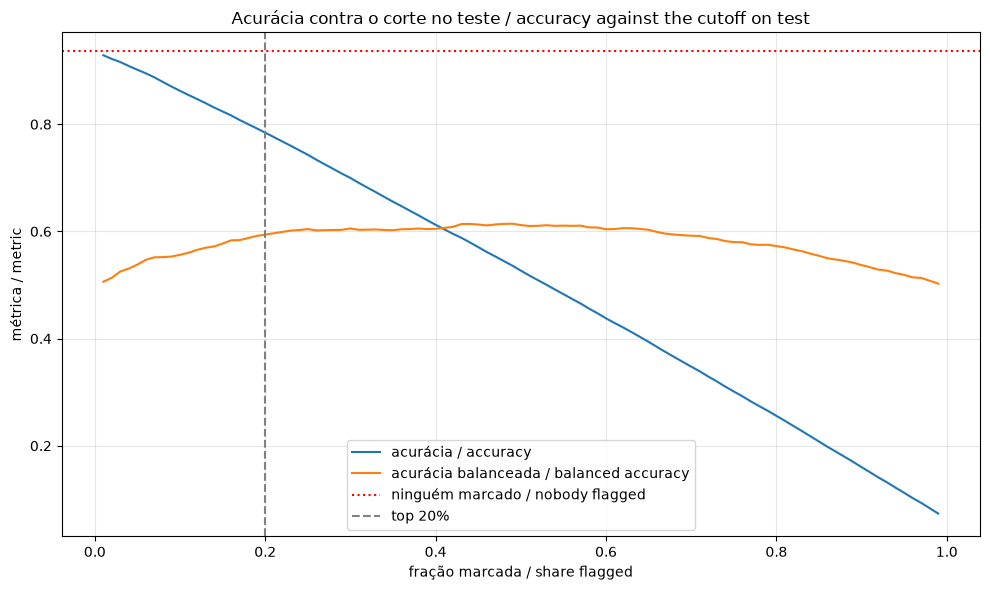

In [38]:
"""Accuracy against the share flagged / acurácia contra a fração marcada."""

# curve over many cutoffs / curva em vários cortes
fracoes = np.linspace(0.01, 0.99, 99)
acuracias = []
balanceadas = []
ordem = np.argsort(-proba_teste, kind="stable")

for fracao in fracoes:
    pred = np.zeros(len(proba_teste), dtype=int)
    pred[ordem[: int(fracao * len(proba_teste))]] = 1
    acuracias.append(accuracy_score(y_test, pred))
    balanceadas.append(balanced_accuracy_score(y_test, pred))

fig, eixo = plt.subplots(figsize=(10, 6))
eixo.plot(fracoes, acuracias, label="acurácia / accuracy")
eixo.plot(fracoes, balanceadas, label="acurácia balanceada / balanced accuracy")
eixo.axhline(1 - y_test.mean(), linestyle=":", color="red", label="ninguém marcado / nobody flagged")
eixo.axvline(0.20, linestyle="--", color="gray", label="top 20%")
eixo.set_xlabel("fração marcada / share flagged")
eixo.set_ylabel("métrica / metric")
eixo.set_title("Acurácia contra o corte no teste / accuracy against the cutoff on test")
eixo.legend()
eixo.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [40]:
"""Classification report of the tuned model on the test set / relatório de classificação do modelo ajustado no conjunto de teste."""

# test probabilities from the tuned pipeline / probabilidades do teste do pipeline ajustado
proba_teste = busca.best_estimator_.predict_proba(X_test)[:, 1]

# flag the top 20% by rank / marca os 20% maiores por ranking
pred_top20 = np.zeros(len(proba_teste), dtype=int)
pred_top20[np.argsort(-proba_teste, kind="stable")[: int(0.20 * len(proba_teste))]] = 1

# classification report at the top 20% cutoff / relatório de classificação no corte do top 20%
print(
    classification_report(
        y_test,
        pred_top20,
        target_names=["sem sinistro / no claim", "sinistro / claim"],
        digits=4,
        zero_division=0,
    )
)

                         precision    recall  f1-score   support

sem sinistro / no claim     0.9501    0.8121    0.8757     10969
       sinistro / claim     0.1204    0.3760    0.1823       750

               accuracy                         0.7842     11719
              macro avg     0.5352    0.5941    0.5290     11719
           weighted avg     0.8970    0.7842    0.8313     11719



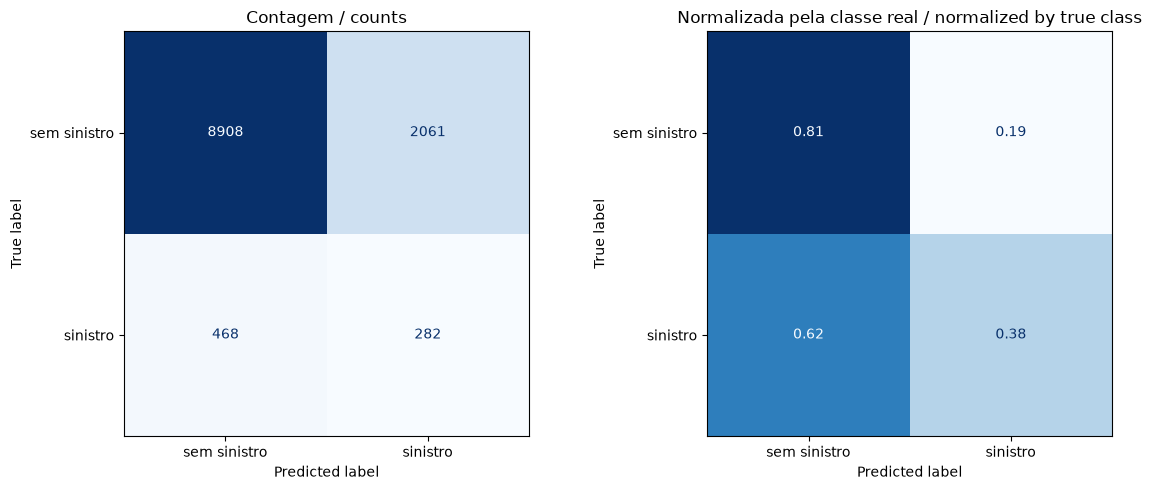

In [41]:
"""Confusion matrix of the tuned model on the test set / matriz de confusão do modelo ajustado no conjunto de teste."""

# test probabilities from the tuned pipeline / probabilidades do teste do pipeline ajustado
proba_teste = busca.best_estimator_.predict_proba(X_test)[:, 1]

# flag the top 20% by rank / marca os 20% maiores por ranking
pred_top20 = np.zeros(len(proba_teste), dtype=int)
pred_top20[np.argsort(-proba_teste, kind="stable")[: int(0.20 * len(proba_teste))]] = 1

# counts and normalized by true class side by side / contagens e normalizada pela classe real lado a lado
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_top20),
    display_labels=["sem sinistro", "sinistro"],
).plot(ax=eixos[0], cmap="Blues", colorbar=False, values_format="d")
eixos[0].set_title("Contagem / counts")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_top20, normalize="true"),
    display_labels=["sem sinistro", "sinistro"],
).plot(ax=eixos[1], cmap="Blues", colorbar=False, values_format=".2f")
eixos[1].set_title("Normalizada pela classe real / normalized by true class")

plt.tight_layout()
plt.show()

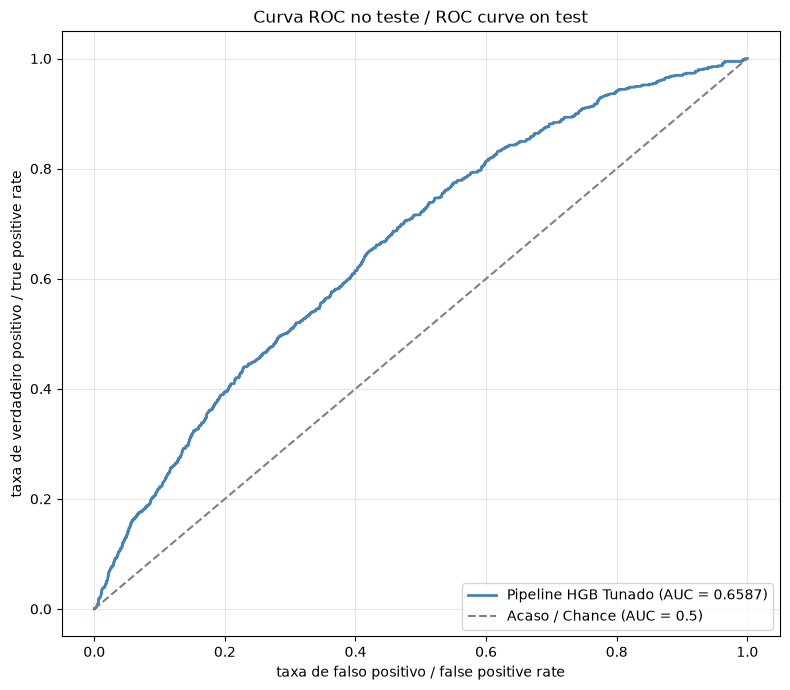

In [42]:
"""ROC curve of the tuned model on the test set / curva ROC do modelo ajustado no conjunto de teste."""

# test probabilities from the tuned pipeline / probabilidades do teste do pipeline ajustado
proba_teste = busca.best_estimator_.predict_proba(X_test)[:, 1]

# false positive rate and true positive rate across thresholds / taxa de falso positivo e verdadeiro positivo em todos os limiares
fpr, tpr, _ = roc_curve(y_test, proba_teste)
area = auc(fpr, tpr)

# single curve with the AUC in the legend / curva única com a AUC na legenda
fig, eixo = plt.subplots(figsize=(8, 7))
eixo.plot(fpr, tpr, linewidth=2, color="steelblue", label=f"Pipeline HGB Tunado (AUC = {area:.4f})")

# diagonal is the chance level / diagonal é o nível do acaso
eixo.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Acaso / Chance (AUC = 0.5)")

eixo.set_xlabel("taxa de falso positivo / false positive rate")
eixo.set_ylabel("taxa de verdadeiro positivo / true positive rate")
eixo.set_title("Curva ROC no teste / ROC curve on test")
eixo.legend(loc="lower right")
eixo.grid(alpha=0.3)

plt.tight_layout()
plt.show()